# 08 · Model Comparison and Selection
**Owner:** Sheetal · **Code:** `evaluation/compare_models.py` · **Inputs:** `results/model_comparison.csv`, `results/model_runs/*.json` (written by notebooks 03–07)

All 5 models: same features, same 5-fold GroupKFold by trip on the 78 clean train trips, same student_test evaluation.

**Primary selection metric: observation-level Top-1 accuracy.** For each GPS point the highest-scoring candidate is compared with the reference arc. This is exactly what route reconstruction consumes. Secondary metrics: macro F1, log loss (the probabilities become HMM emissions), route continuity, inference time.

In [1]:
import os, sys
# run from the repository root regardless of where the notebook lives
_p = os.path.abspath(os.getcwd())
while not os.path.isdir(os.path.join(_p, "pathsnap")):
    _p = os.path.dirname(_p)
os.chdir(_p); sys.path.insert(0, _p)
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 110
print("repo root:", os.getcwd())
from evaluation.compare_models import load_comparison, make_all_plots
comp = load_comparison()
cols = ["family", "cv_macro_f1_mean", "cv_macro_f1_std", "cv_top1_mean", "cv_top1_std", "train_top1", "test_top1", "test_macro_f1",
        "test_precision", "test_recall", "test_logloss", "test_cand_miss_rate", "test_route_continuity_clf", "train_time_s", "infer_ms_per_trip"]
comp[cols].round(4)

repo root: C:\Users\shrey\OneDrive\Documents\ML Hackathon\PathSnap_7_H


,family,cv_macro_f1_mean,cv_macro_f1_std,cv_top1_mean,cv_top1_std,train_top1,test_top1,test_macro_f1,test_precision,test_recall,test_logloss,test_cand_miss_rate,test_route_continuity_clf,train_time_s,infer_ms_per_trip
model,,,,,,,,,,,,,,,
logreg,Linear/probabilistic,0.8812,0.0126,0.8703,0.0261,0.8712,0.8637,0.8790,0.6912,0.9487,0.1667,0.0028,0.9479,1.49,3.39
knn,Instance-based,0.9188,0.0153,0.8649,0.0320,0.9908,0.8626,0.9162,0.8677,0.8454,0.1435,0.0028,0.9428,0.06,1430.83
random_forest,Ensemble (bagging),0.9209,0.0129,0.8719,0.0275,0.9300,0.8775,0.9212,0.8164,0.9236,0.1034,0.0028,0.9497,56.99,53.13
mlp,Neural network,0.9193,0.0199,0.8688,0.0319,0.8855,0.8707,0.9223,0.8686,0.8656,0.0957,0.0028,0.9541,86.74,11.11
lightgbm,Boosting,0.9114,0.0130,0.8737,0.0272,0.9175,0.8827,0.9133,0.7779,0.9481,0.1149,0.0028,0.9547,6.45,42.80


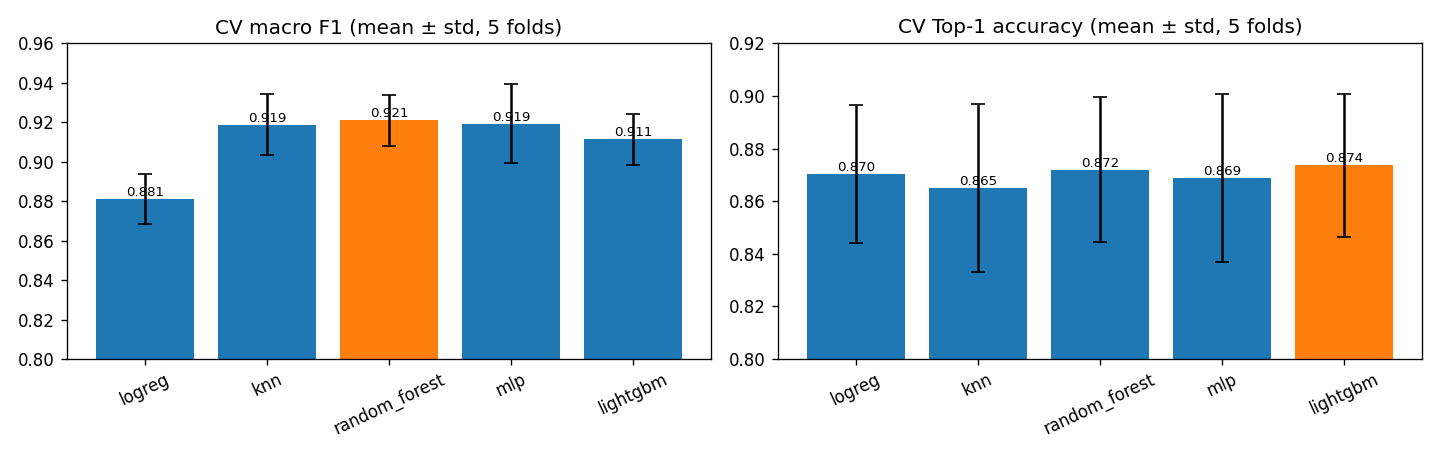

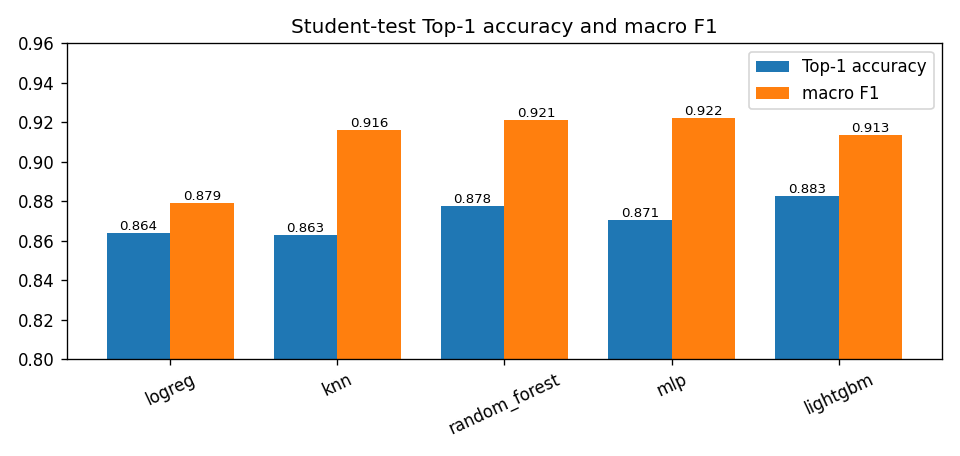

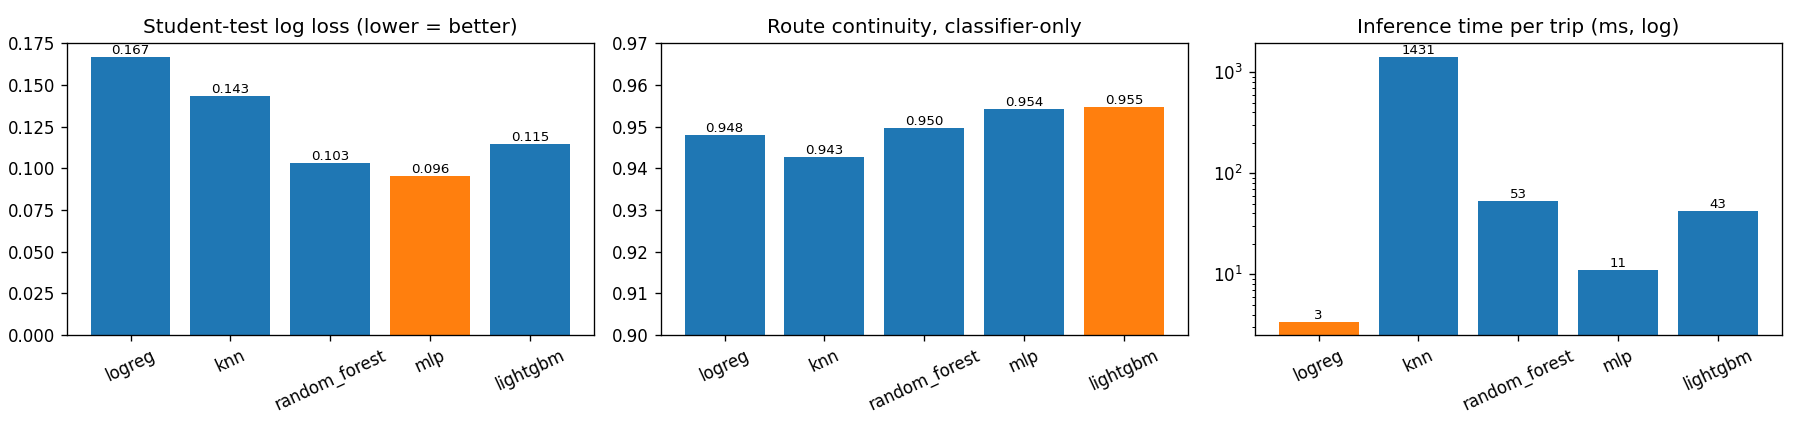

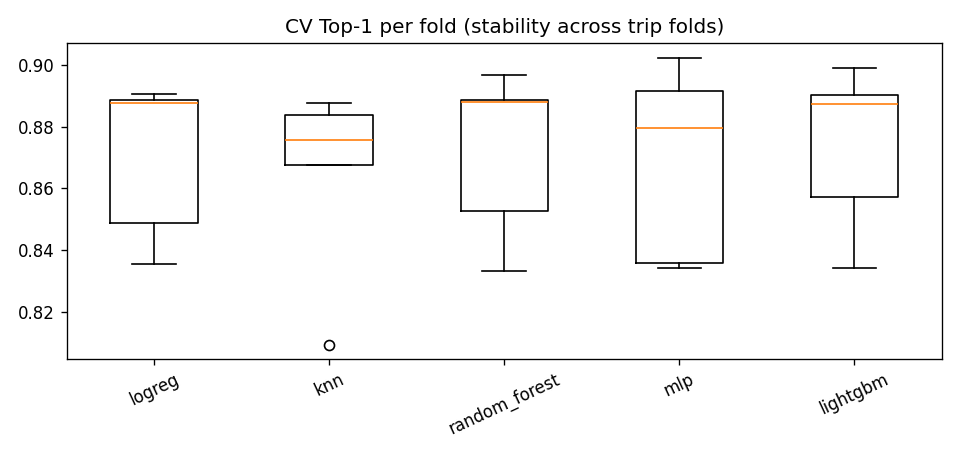

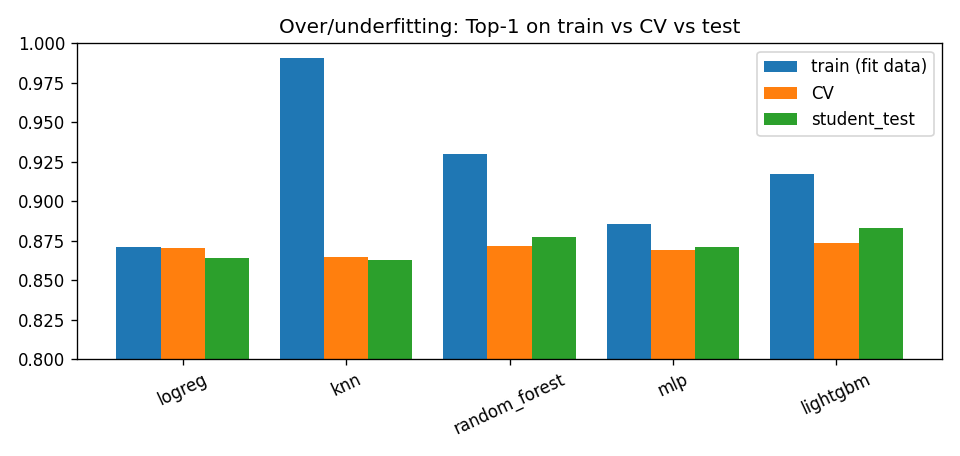

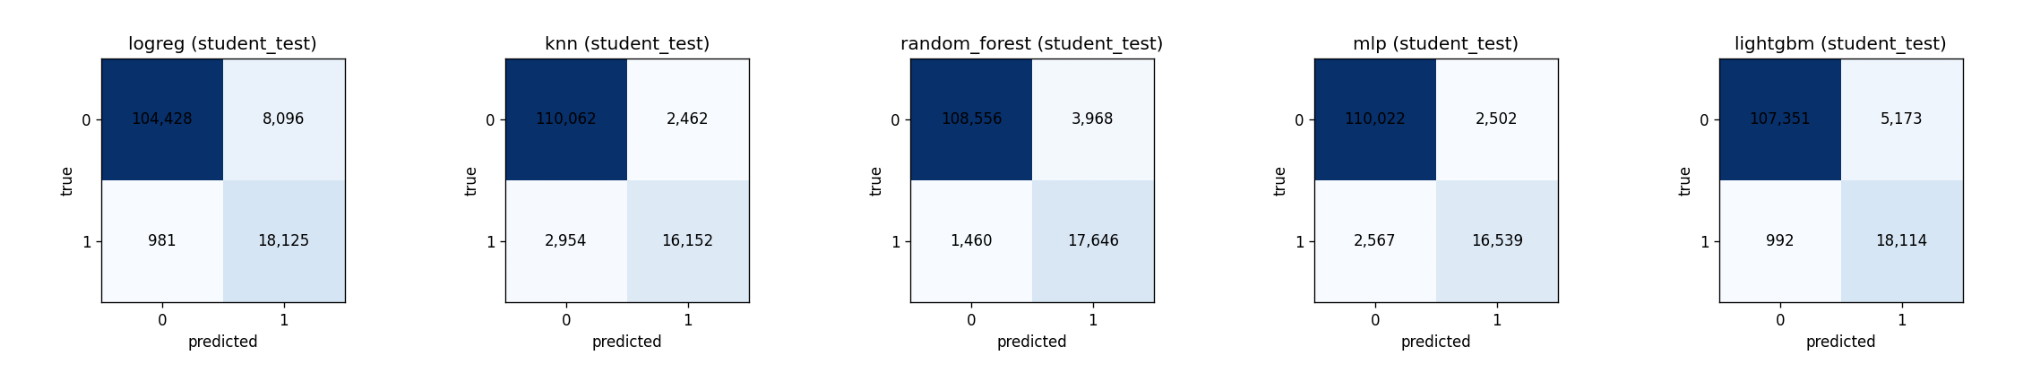

In [2]:
paths = make_all_plots(comp)
from IPython.display import Image, display
for p in paths: display(Image(p))

## Selection

In [3]:
best_cv = comp.cv_top1_mean.idxmax(); best_test = comp.test_top1.idxmax()
print("best CV Top-1     :", best_cv, round(comp.cv_top1_mean.max(), 4))
print("best test Top-1   :", best_test, round(comp.test_top1.max(), 4))
print("best CV macro F1  :", comp.cv_macro_f1_mean.idxmax(), round(comp.cv_macro_f1_mean.max(), 4))
print("best test log loss:", comp.test_logloss.idxmin(), round(comp.test_logloss.min(), 4))
print("fastest inference :", comp.infer_ms_per_trip.idxmin())
print("\nspread of CV Top-1 across models: %.4f vs typical fold std %.4f" % (comp.cv_top1_mean.max() - comp.cv_top1_mean.min(), comp.cv_top1_std.mean()))

best CV Top-1     : lightgbm 0.8737
best test Top-1   : lightgbm 0.8827
best CV macro F1  : random_forest 0.9209
best test log loss: mlp 0.0957
fastest inference : logreg

spread of CV Top-1 across models: 0.0088 vs typical fold std 0.0289


**Decision: LightGBM.**
1. Highest **CV Top-1** and highest **student-test Top-1** (the primary metric), plus the best classifier-only route continuity.
2. About 6 s per fit: a Bayesian search with dozens of trials is affordable (Random Forest needs about 65 s per fit).
3. Fast inference (tens of ms per trip) and a small model file (about 1 MB vs about 70 MB for RF): suitable for the live API.
4. Outputs log-loss-trained probabilities for the HMM.

**Honest caveats:**
- Top-1 differences between models are smaller than the fold standard deviation: the features carry most of the signal.
- RF and MLP have a higher macro F1 and a lower log loss untuned. Bayesian tuning (notebook 09) closes this gap for LightGBM.
- KNN is ruled out for deployment (about 2 s per trip; strong overfitting, train Top-1 0.99 vs CV 0.86).
- Logistic Regression underfits slightly (train ≈ CV, lowest F1).